# 04: is a neural network worth it on the kiosks? (milestone m4)

The director's question: the kiosks run on modest CPUs, the team is small, the budget is limited. Is a neural network
worth it, or would a simpler classical model do the job?

To answer with numbers (not opinions), we put four models side by side, on the **same split and the same 250 test
paintings** as notebooks 01 to 03:

1. a **classical model**: hand-made features (colour histograms + HOG edge descriptors) and a logistic regression or an
   SVM from scikit-learn;
2. the **dense network** of m1 (6.3 million weights);
3. the **fine-tuned ResNet-18** of m3;
4. a **hybrid**: the frozen ResNet-18 used as a feature extractor, and a logistic regression on top of its 512 numbers.

For each: test accuracy, size on disk, and prediction time of one image on **one CPU thread** (a kiosk is not a laptop
with 8 cores).

## Imports and helpers

In [1]:
import os, io, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from skimage.feature import hog
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

DATA_DIR = "data/wikiart_genre5"
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(4)          # for training; the latency measures below use ONE thread
device = "cpu"


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

## The data, exactly as in notebooks 01 to 03

Same loading, same split by artist (seed 0: 1 000 / 250 / 250 images, no named artist in two sets).

In [2]:
folder = datasets.ImageFolder(DATA_DIR)
CLASSES = folder.classes
images = np.stack([np.array(img) for img, _ in folder])
X_full = torch.tensor(images).permute(0, 3, 1, 2).float() / 255
y_full = torch.tensor(folder.targets)

meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv")).set_index("path")
artist = [meta.loc[os.path.relpath(p, DATA_DIR), "artist"] for p, _ in folder.samples]
group = [a if a != "Unknown Artist" else f"unknown_{i}" for i, a in enumerate(artist)]
names = sorted(set(group))
members = {g: [i for i, h in enumerate(group) if h == g] for g in names}

order = torch.randperm(len(names), generator=torch.Generator().manual_seed(0)).tolist()
per_class = torch.bincount(y_full) // 6
filled = {"test": torch.zeros(len(CLASSES), dtype=torch.int64), "val": torch.zeros(len(CLASSES), dtype=torch.int64)}
split = {"train": [], "val": [], "test": []}
for k in order:
    idx = members[names[k]]
    counts = torch.bincount(y_full[idx], minlength=len(CLASSES))
    s = next((s for s in ["test", "val"] if (filled[s] + counts <= per_class).all()), "train")
    if s != "train":
        filled[s] += counts
    split[s] += idx
train_idx, val_idx, test_idx = (torch.tensor(sorted(split[s])) for s in ["train", "val", "test"])
X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
X_test_raw, y_test = X_full[test_idx], y_full[test_idx]

named = {s: {artist[i] for i in split[s]} - {"Unknown Artist"} for s in split}
assert not (named["train"] & named["val"] or named["train"] & named["test"] or named["val"] & named["test"])
print(f"train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)} | no named artist in two sets")

train 1000, val 250, test 250 | no named artist in two sets


## 1. The classical model: hand-made features + logistic regression / SVM

A classical model cannot read 49 152 raw pixels well, so a human describes the image with a few hundred numbers:

- **colour**: for each of the 3 RGB channels, a 16-bin histogram, plus the mean and the standard deviation of the channel
  (54 numbers). Still lifes and portraits have different palettes than landscapes (sky, vegetation);
- **shape / edges**: a **HOG** (histogram of oriented gradients) on the grey image, 16 x 16 pixel cells, 9 orientations
  (1 764 numbers). It describes where the edges are and in which direction: horizon lines, vertical buildings, faces...

The features are standardised with the training statistics, then we try a logistic regression and an RBF-SVM. The
regularisation `C` is chosen **on the validation set**.

In [3]:
def hand_features(x):
    """x: one image (3, 128, 128) in [0, 1] -> vector of 54 colour + 1764 HOG numbers."""
    a = x.numpy()
    colour = [np.histogram(a[c], bins=16, range=(0, 1))[0] / a[c].size for c in range(3)]
    stats = [[a[c].mean(), a[c].std()] for c in range(3)]
    grey = a.mean(axis=0)
    shape = hog(grey, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), feature_vector=True)
    return np.concatenate(colour + stats + [shape])


t0 = time.time()
F_train = np.stack([hand_features(x) for x in X_train_raw])
F_val = np.stack([hand_features(x) for x in X_val_raw])
F_test = np.stack([hand_features(x) for x in X_test_raw])
print("features:", F_train.shape, f"| extracted in {time.time() - t0:.0f} s")

results_val = {}
fitted = {}
for name, make in [("logreg C=0.001", lambda: LogisticRegression(C=0.001, max_iter=2000)),
                   ("logreg C=0.01", lambda: LogisticRegression(C=0.01, max_iter=2000)),
                   ("logreg C=0.1", lambda: LogisticRegression(C=0.1, max_iter=2000)),
                   ("svm rbf C=1", lambda: SVC(C=1)),
                   ("svm rbf C=10", lambda: SVC(C=10))]:
    pipe = make_pipeline(StandardScaler(), make()).fit(F_train, y_train.numpy())
    results_val[name] = pipe.score(F_val, y_val.numpy())
    fitted[name] = pipe
    print(f"{name:16s} train acc {pipe.score(F_train, y_train.numpy()):.3f} | val acc {results_val[name]:.3f}")
best_classical = max(results_val, key=results_val.get)
clf_classical = fitted[best_classical]
print("chosen on validation:", best_classical)

features: (1000, 1818) | extracted in 3 s
logreg C=0.001   train acc 0.828 | val acc 0.548


logreg C=0.01    train acc 0.990 | val acc 0.516


logreg C=0.1     train acc 1.000 | val acc 0.500


svm rbf C=1      train acc 0.962 | val acc 0.548


svm rbf C=10     train acc 1.000 | val acc 0.580
chosen on validation: svm rbf C=10


## 2. The dense network of m1

Same architecture (49 152 - 128 sigmoid - 5), same recipe as m2 (SGD, lr 0.2), with early stopping on the validation
loss (patience 5, kept epoch = the best one), as decided in the failure diagnosis of m2.

In [4]:
import copy
mean, std = X_train_raw.mean().item(), X_train_raw.std().item()
dense_train = DataLoader(TensorDataset((X_train_raw - mean) / std, y_train), batch_size=64, shuffle=True)
dense_val = DataLoader(TensorDataset((X_val_raw - mean) / std, y_val), batch_size=1000)
dense_test = DataLoader(TensorDataset((X_test_raw - mean) / std, y_test), batch_size=1000)
loss_fn = nn.CrossEntropyLoss()

torch.manual_seed(0)
dense = nn.Sequential(nn.Flatten(), nn.Linear(3 * 128 * 128, 128), nn.Sigmoid(), nn.Linear(128, len(CLASSES)))
opt = torch.optim.SGD(dense.parameters(), lr=0.2)
torch.manual_seed(1)
best, best_state, wait = float("inf"), None, 0
for epoch in range(1, 31):
    dense.train()
    for xb, yb in dense_train:
        opt.zero_grad(); loss_fn(dense(xb), yb).backward(); opt.step()
    vl, va = evaluate(dense, dense_val, loss_fn)
    if vl < best:
        best, best_state, wait, best_epoch = vl, copy.deepcopy(dense.state_dict()), 0, epoch
    else:
        wait += 1
        if wait >= 5:
            break
dense.load_state_dict(best_state)
print(f"stopped at epoch {epoch}, kept epoch {best_epoch}")
print("validation (kept model):", evaluate(dense, dense_val, loss_fn))

stopped at epoch 10, kept epoch 5
validation (kept model): (1.4817514419555664, 0.408)


## 3. The fine-tuned ResNet-18 of m3

Same recipe as m3: new head trained alone for 3 epochs (Adam 3e-3), then `layer4` unfrozen with lr 1e-4 and the head at
1e-3 for 3 epochs, batch norm kept in `eval()` mode. This re-runs m3 so that we can time and save the model.

In [5]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
prepare = lambda X: (X - IMAGENET_MEAN) / IMAGENET_STD
res_train = DataLoader(TensorDataset(prepare(X_train_raw), y_train), batch_size=64, shuffle=True)
res_val = DataLoader(TensorDataset(prepare(X_val_raw), y_val), batch_size=250)
res_test = DataLoader(TensorDataset(prepare(X_test_raw), y_test), batch_size=250)


def fit_transfer(model, optimizer, n_epochs):
    torch.manual_seed(1)
    for epoch in range(n_epochs):
        model.eval()                                   # batch norm keeps its ImageNet statistics
        for xb, yb in res_train:
            optimizer.zero_grad(); loss_fn(model(xb), yb).backward(); optimizer.step()
        vl, va = evaluate(model, res_val, loss_fn)
        print(f"epoch {epoch + 1}: val loss {vl:.3f} | val acc {va:.3f}")


torch.manual_seed(0)
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(512, len(CLASSES))
for p in resnet.parameters():
    p.requires_grad = False
for p in resnet.fc.parameters():
    p.requires_grad = True
t0 = time.time()
fit_transfer(resnet, torch.optim.Adam(resnet.fc.parameters(), lr=3e-3), 3)
for p in resnet.layer4.parameters():
    p.requires_grad = True
fit_transfer(resnet, torch.optim.Adam([{"params": resnet.layer4.parameters(), "lr": 1e-4},
                                       {"params": resnet.fc.parameters(), "lr": 1e-3}]), 3)
print(f"training time of the ResNet: {time.time() - t0:.0f} s")

epoch 1: val loss 0.750 | val acc 0.728


epoch 2: val loss 0.741 | val acc 0.740


epoch 3: val loss 0.722 | val acc 0.728


epoch 1: val loss 0.786 | val acc 0.700


epoch 2: val loss 0.870 | val acc 0.740


epoch 3: val loss 0.985 | val acc 0.744
training time of the ResNet: 110 s


## 4. The hybrid: frozen ResNet features + logistic regression

No fine-tuning at all: the pretrained ResNet-18 (without its head) turns each painting into 512 numbers, and a classical
logistic regression reads them. No gradient descent on the network, only one `fit` of scikit-learn.

In [6]:
torch.manual_seed(0)
backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
backbone.fc = nn.Identity()
backbone.eval()


def embed(X):
    with torch.no_grad():
        return torch.cat([backbone(prepare(X[i:i + 250])) for i in range(0, len(X), 250)]).numpy()


E_train, E_val, E_test = embed(X_train_raw), embed(X_val_raw), embed(X_test_raw)
hyb_val = {}
hyb_fit = {}
for C_ in [0.001, 0.01, 0.1, 1]:
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C_, max_iter=3000)).fit(E_train, y_train.numpy())
    hyb_val[C_] = pipe.score(E_val, y_val.numpy()); hyb_fit[C_] = pipe
    print(f"logreg C={C_:<6} val acc {hyb_val[C_]:.3f}")
C_best = max(hyb_val, key=hyb_val.get)
clf_hybrid = hyb_fit[C_best]
print("chosen on validation: C =", C_best)

logreg C=0.001  val acc 0.724
logreg C=0.01   val acc 0.748


logreg C=0.1    val acc 0.704
logreg C=1      val acc 0.704
chosen on validation: C = 0.01


## Test accuracy: each model is measured once

The four models are chosen (on validation only). Now, once, on the 250 test paintings by artists never seen in training.

In [7]:
_, acc_dense = evaluate(dense, dense_test, loss_fn)
_, acc_resnet = evaluate(resnet, res_test, loss_fn)
acc_classical = clf_classical.score(F_test, y_test.numpy())
acc_hybrid = clf_hybrid.score(E_test, y_test.numpy())
test_acc = {"classical (HOG+colour, " + best_classical + ")": acc_classical,
            "dense network (m1/m2)": acc_dense,
            "ResNet-18 frozen + logreg": acc_hybrid,
            "ResNet-18 fine-tuned (m3)": acc_resnet}
for k, v in test_acc.items():
    print(f"{k:50s} {v:.3f}  ({round(v * 250)}/250)")

# the 95 % uncertainty of an accuracy measured on 250 images
for k, v in test_acc.items():
    print(f"{k:50s} +/- {1.96 * np.sqrt(v * (1 - v) / 250):.3f}")

classical (HOG+colour, svm rbf C=10)               0.516  (129/250)
dense network (m1/m2)                              0.388  (97/250)
ResNet-18 frozen + logreg                          0.768  (192/250)
ResNet-18 fine-tuned (m3)                          0.796  (199/250)
classical (HOG+colour, svm rbf C=10)               +/- 0.062
dense network (m1/m2)                              +/- 0.060
ResNet-18 frozen + logreg                          +/- 0.052
ResNet-18 fine-tuned (m3)                          +/- 0.050


**Reading the uncertainty.** With 250 test images, an accuracy has a 95 % margin of about ±0.05 (±0.06 near 0.5): two
models closer than that cannot be told apart. The comparisons below are made with that in mind.

## Cost on a kiosk: size on disk and latency on ONE CPU thread

- **Size**: the number of bytes of the saved model (`state_dict` for PyTorch, `pickle` for scikit-learn).
- **Latency**: time to predict **one** painting from a 128 x 128 image already in memory, **including the feature
  extraction** for the classical models (HOG is computed at prediction time too!). Median of 50 runs after 5 warm-ups,
  with `torch.set_num_threads(1)`.

In [8]:
torch.set_num_threads(1)


def size_torch(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.tell() / 1e6


def size_pickle(o):
    return len(pickle.dumps(o)) / 1e6


def median_ms(fn, runs=50, warmup=5):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(runs):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return 1000 * float(np.median(t))


x1 = X_test_raw[:1]
dense.eval(); resnet.eval()


def run_classical():
    return clf_classical.predict(hand_features(x1[0])[None])


def run_dense():
    with torch.no_grad():
        return dense((x1 - mean) / std).argmax(1)


def run_resnet():
    with torch.no_grad():
        return resnet(prepare(x1)).argmax(1)


def run_hybrid():
    with torch.no_grad():
        return clf_hybrid.predict(backbone(prepare(x1)).numpy())


cost = pd.DataFrame({
    "test acc": [acc_classical, acc_dense, acc_hybrid, acc_resnet],
    "size (MB)": [size_pickle(clf_classical), size_torch(dense), size_torch(backbone) + size_pickle(clf_hybrid), size_torch(resnet)],
    "latency / image (ms, 1 thread)": [median_ms(run_classical), median_ms(run_dense), median_ms(run_hybrid), median_ms(run_resnet)],
    "parameters": [np.nan, count_parameters(dense), count_parameters(backbone), count_parameters(resnet)],
}, index=["classical (HOG + colour + " + best_classical + ")", "dense network", "ResNet-18 frozen + logreg", "ResNet-18 fine-tuned"])
print(cost.round(3).to_string())
cost.round(4).to_csv("results_m4.csv")
torch.set_num_threads(4)

                                         test acc  size (MB)  latency / image (ms, 1 thread)  parameters
classical (HOG + colour + svm rbf C=10)     0.516     14.538                           2.372         NaN
dense network                               0.388     25.171                           0.483   6292229.0
ResNet-18 frozen + logreg                   0.768     44.816                          12.855  11176512.0
ResNet-18 fine-tuned                        0.796     44.793                          12.408  11179077.0


In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, row in cost.iterrows():
    ax.scatter(row["latency / image (ms, 1 thread)"], row["test acc"], s=60 + row["size (MB)"] * 3)
    ax.annotate(name.split(" (")[0], (row["latency / image (ms, 1 thread)"], row["test acc"]), textcoords="offset points",
                xytext=(-10, 8) if row["latency / image (ms, 1 thread)"] > 8 else (8, 8),
                ha="right" if row["latency / image (ms, 1 thread)"] > 8 else "left", fontsize=8)
ax.axhline(0.2, ls=":", c="grey"); ax.text(ax.get_xlim()[0], 0.205, "chance", fontsize=8, color="grey")
ax.set_xscale("log"); ax.set_xlim(0.3, 30); ax.set_xlabel("latency per image on 1 CPU thread (ms, log scale)"); ax.set_ylabel("test accuracy")
ax.set_title("Accuracy vs cost (bubble area ~ size on disk)")
plt.tight_layout(); plt.savefig("tradeoff_m4.png", dpi=150); plt.show()

/var/folders/j8/5x9w0xns1js8zq9gvppp9y2m0000gn/T/ipykernel_40997/1675823992.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.savefig("tradeoff_m4.png", dpi=150); plt.show()


## Where does each model fail? Confusion matrices on the test set

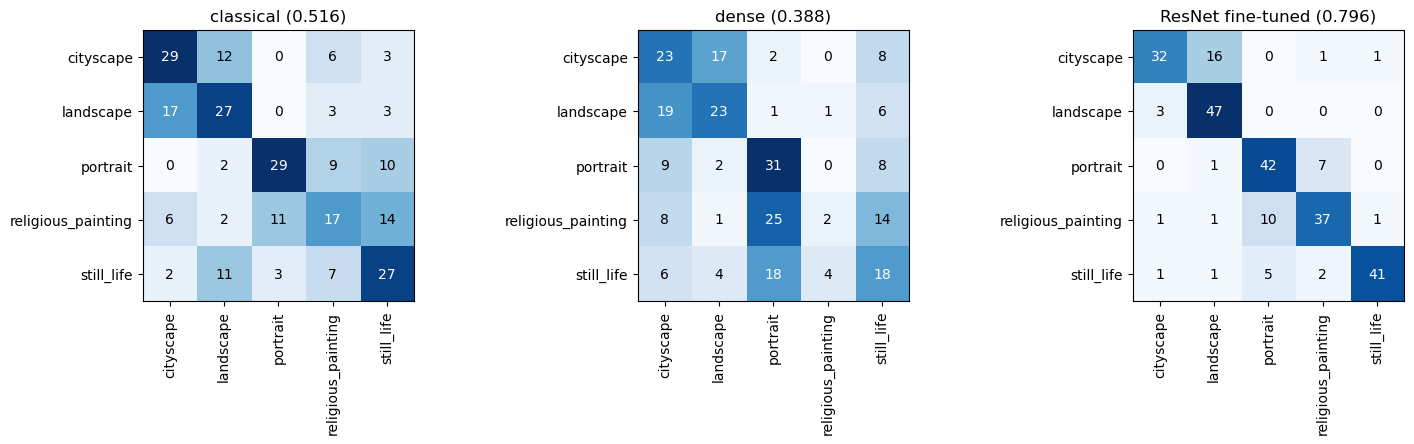

In [10]:
preds = {"classical": clf_classical.predict(F_test),
         "dense": dense(((X_test_raw - mean) / std)).argmax(1).detach().numpy(),
         "ResNet fine-tuned": resnet(prepare(X_test_raw)).argmax(1).detach().numpy()}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test.numpy(), p)
    ax.imshow(cm, cmap="Blues")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels(CLASSES, rotation=90); ax.set_yticks(range(5)); ax.set_yticklabels(CLASSES)
    ax.set_title(f"{name} ({(p == y_test.numpy()).mean():.3f})")
plt.tight_layout(); plt.savefig("confusions_m4.png", dpi=130); plt.show()

## Recommendation to the director

(see the numbers above; the written conclusion is in the `README.md` and in the presentation)